#Import Data & Spark Set-Up

Reproduces RQ3.1–3.4 from RQ3_Pandas.ipynb on S1 (originated + denied). Spark performs application-level aggregations; only small aggregated tables are collected for plotting and comparison. Rates are percentages, gaps are percentage points. All results are exported separately from Pandas.

In [1]:
%pip install -q pyspark us geopandas
from google.colab import drive
drive.mount('/content/drive')
import os, sys, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel
from IPython.display import display
BASE = '/content/drive/MyDrive/hmda/'
OUT = BASE + 'rq3_spark/'
PANDAS_OUT = BASE + 'rq3_pandas/'
os.makedirs(OUT, exist_ok=True)
sys.path.insert(0, BASE)
import rules
spark = (SparkSession.builder.appName('HMDA2024_RQ3')
         .config('spark.driver.memory','8g')
         .config('spark.sql.shuffle.partitions','64').getOrCreate())
COLS = ['action_taken','denied_flag','loan_type','loan_purpose','lien_status',
        'occupancy_type','construction_method','derived_loan_product_type','state_code','lei']
source = BASE + 'clean_spark/S1_orig_denied'
# Copy to fresh local storage to avoid stale parquet files.
local = '/content/rq3_s1_spark'
if os.path.exists(local): shutil.rmtree(local)
shutil.copytree(source, local) if os.path.isdir(source) else shutil.copy2(source, local)
S1 = spark.read.parquet(local).select(*COLS).persist(StorageLevel.MEMORY_AND_DISK)
counts = S1.agg(F.count('*').alias('n'), F.sum('denied_flag').alias('denied'),
                F.sum(F.when(F.col('denied_flag').isin(0,1),0).otherwise(1)).alias('invalid')).first()
N = int(counts.n); DENIED = int(counts.denied)
assert N > 0 and counts.invalid == 0, 'Invalid target in S1'
BASELINE = DENIED / N * 100
print(f'S1: {N:,} | Denied: {DENIED:,} | Baseline: {BASELINE:.6f}%')
S1.printSchema()


Mounted at /content/drive
S1: 8,300,547 | Denied: 2,103,462 | Baseline: 25.341246%
root
 |-- action_taken: string (nullable = true)
 |-- denied_flag: byte (nullable = true)
 |-- loan_type: string (nullable = true)
 |-- loan_purpose: string (nullable = true)
 |-- lien_status: string (nullable = true)
 |-- occupancy_type: string (nullable = true)
 |-- construction_method: string (nullable = true)
 |-- derived_loan_product_type: string (nullable = true)
 |-- state_code: string (nullable = true)
 |-- lei: string (nullable = true)



# Data Understanding

In [2]:
exprs = []
for c in COLS:
    exprs.extend([F.countDistinct(c).alias(c+'_unique'), F.sum(F.col(c).isNull().cast('long')).alias(c+'_missing')])
r = S1.agg(*exprs).first().asDict()
overview = pd.DataFrame([{'variable':c,'dtype':dict(S1.dtypes)[c], 'unique':r[c+'_unique'], 'missing':r[c+'_missing'], 'missing_pct':r[c+'_missing']/N*100} for c in COLS])
display(overview.round(4))
overview.to_csv(OUT+'variable_overview.csv',index=False)
CAT_COLS = ['loan_type','loan_purpose','lien_status','occupancy_type','construction_method','derived_loan_product_type']
for c in CAT_COLS:
    print(c)
    display(S1.groupBy(c).count().orderBy(F.desc('count')).toPandas())

,variable,dtype,unique,missing,missing_pct
0,action_taken,string,2,0,0.0000
1,denied_flag,tinyint,2,0,0.0000
2,loan_type,string,4,0,0.0000
3,loan_purpose,string,6,0,0.0000
4,lien_status,string,2,0,0.0000
5,occupancy_type,string,3,0,0.0000
6,construction_method,string,2,0,0.0000
7,derived_loan_product_type,string,8,0,0.0000
8,state_code,string,54,36577,0.4407
9,lei,string,4909,0,0.0000


loan_type


,loan_type,count
0,1,6601706
1,2,1072243
2,3,584996
3,4,41602


loan_purpose


,loan_purpose,count
0,1,4158055
1,32,1165962
2,4,1078317
3,2,972499
4,31,922327
5,5,3387


lien_status


... (3 outputs left out)

construction_method


,construction_method,count
0,1,7846538
1,2,454009


derived_loan_product_type


,derived_loan_product_type,count
0,Conventional:First Lien,4323685
1,Conventional:Subordinate Lien,2278021
2,FHA:First Lien,1071125
3,VA:First Lien,584977
4,FSA/RHS:First Lien,37407
5,FSA/RHS:Subordinate Lien,4195
6,FHA:Subordinate Lien,1118
7,VA:Subordinate Lien,19


## RQ3.1 — Denial Rate by Loan Characteristics

In [3]:
# Loan characteristics mapping

LABELS = {
    "loan_type": {
        "1": "Conventional",
        "2": "FHA",
        "3": "VA",
        "4": "FSA/RHS"
    },
    "loan_purpose": {
        "1": "Home purchase",
        "2": "Home improvement",
        "31": "Refinancing",
        "32": "Cash-out refinancing",
        "4": "Other purpose",
        "5": "Not applicable"
    },
    "lien_status": {
        "1": "First lien",
        "2": "Subordinate lien"
    },
    "occupancy_type": {
        "1": "Principal residence",
        "2": "Second residence",
        "3": "Investment property"
    },
    "construction_method": {
        "1": "Site-built",
        "2": "Manufactured home"
    }
}

In [4]:
def denial_summary(df, col, total=None):
    total = N if total is None else total
    result = (df.groupBy(col).agg(F.count('*').alias('applications'),
              F.sum('denied_flag').alias('denied'))
              .withColumn('originated',F.col('applications')-F.col('denied'))
              .withColumn('denial_rate',F.col('denied')/F.col('applications')*100)
              .withColumn('volume_share',F.col('applications')/F.lit(total)*100)
              .withColumn('gap_vs_baseline_pp',F.col('denial_rate')-F.lit(BASELINE))
              .orderBy(F.desc('denial_rate'),F.desc('applications'),F.asc_nulls_last(col)))
    return result.toPandas()
print(f'Baseline denial rate: {BASELINE:.2f}%')

Baseline denial rate: 25.34%


In [5]:
RQ3_RESULTS = {}

for col in [
    "lien_status",
    "occupancy_type",
    "construction_method",
    "derived_loan_product_type"
]:
    result = denial_summary(S1, col)

    if col in LABELS:
        result["label"] = result[col].map(LABELS[col])
    else:
        result["label"] = result[col]

    RQ3_RESULTS[col] = result

    print(f"\n--- {col} ---")
    display(result.round(2))

    result.to_csv(
        OUT + f"denial_by_{col}.csv",
        index=False
    )


--- lien_status ---


,lien_status,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,label
0,2,2283353,857003,1426350,37.53,27.51,12.19,Subordinate lien
1,1,6017194,1246459,4770735,20.71,72.49,-4.63,First lien



--- occupancy_type ---


,occupancy_type,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,label
0,1,7468387,1929249,5539138,25.83,89.97,0.49,Principal residence
1,2,163409,39601,123808,24.23,1.97,-1.11,Second residence
2,3,668751,134612,534139,20.13,8.06,-5.21,Investment property



--- construction_method ---


,construction_method,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,label
0,2,454009,272372,181637,59.99,5.47,34.65,Manufactured home
1,1,7846538,1831090,6015448,23.34,94.53,-2.00,Site-built



--- derived_loan_product_type ---


,derived_loan_product_type,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,label
0,VA:Subordinate Lien,19,13,6,68.42,0.00,43.08,VA:Subordinate Lien
1,FHA:Subordinate Lien,1118,580,538,51.88,0.01,26.54,FHA:Subordinate Lien
2,Conventional:Subordinate Lien,2278021,856082,1421939,37.58,27.44,12.24,Conventional:Subordinate Lien
3,FHA:First Lien,1071125,239866,831259,22.39,12.90,-2.95,FHA:First Lien
4,Conventional:First Lien,4323685,907475,3416210,20.99,52.09,-4.35,Conventional:First Lien
5,VA:First Lien,584977,94158,490819,16.10,7.05,-9.25,VA:First Lien
6,FSA/RHS:First Lien,37407,4960,32447,13.26,0.45,-12.08,FSA/RHS:First Lien
7,FSA/RHS:Subordinate Lien,4195,328,3867,7.82,0.05,-17.52,FSA/RHS:Subordinate Lien


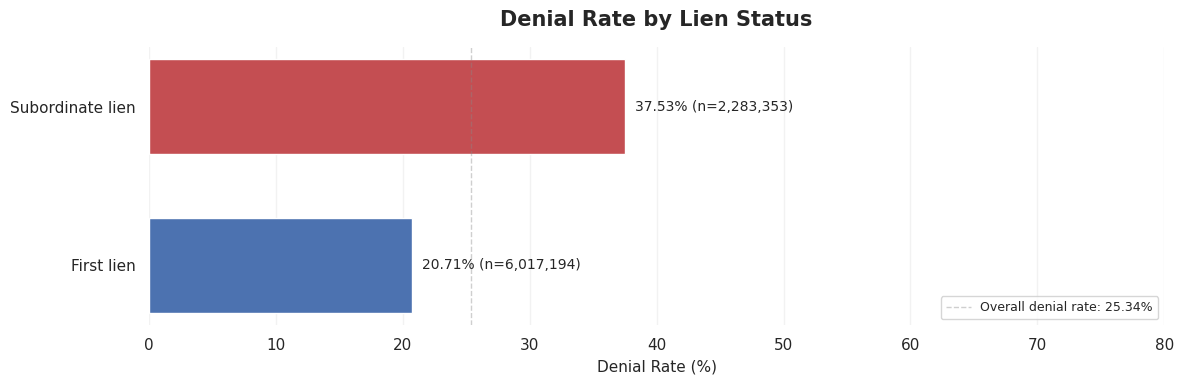

Updated: /content/drive/MyDrive/hmda/rq3_spark/denial_by_lien_status.png
Groups displayed: 2/2
Groups excluded from chart: 0



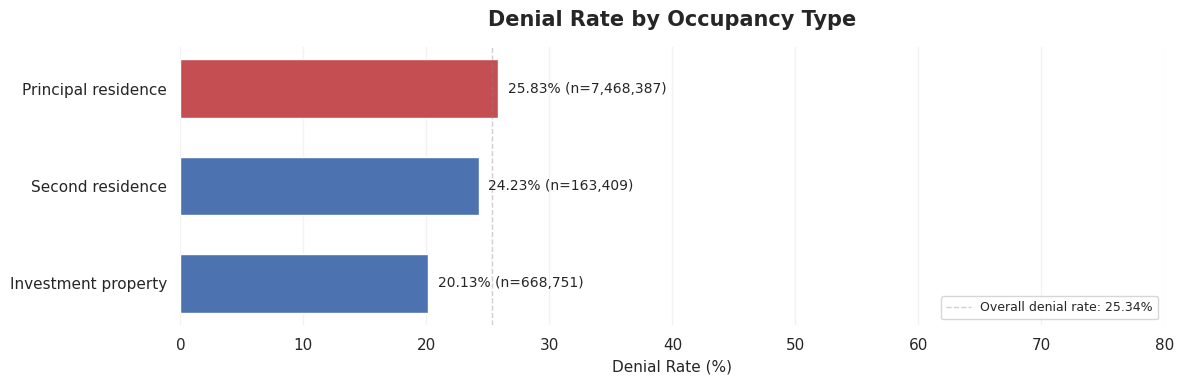

Updated: /content/drive/MyDrive/hmda/rq3_spark/denial_by_occupancy_type.png
Groups displayed: 3/3
Groups excluded from chart: 0



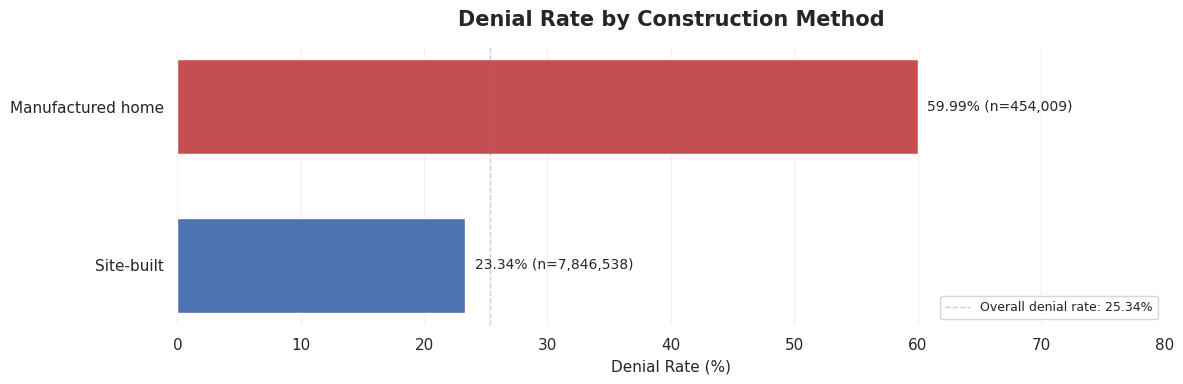

Updated: /content/drive/MyDrive/hmda/rq3_spark/denial_by_construction_method.png
Groups displayed: 2/2
Groups excluded from chart: 0



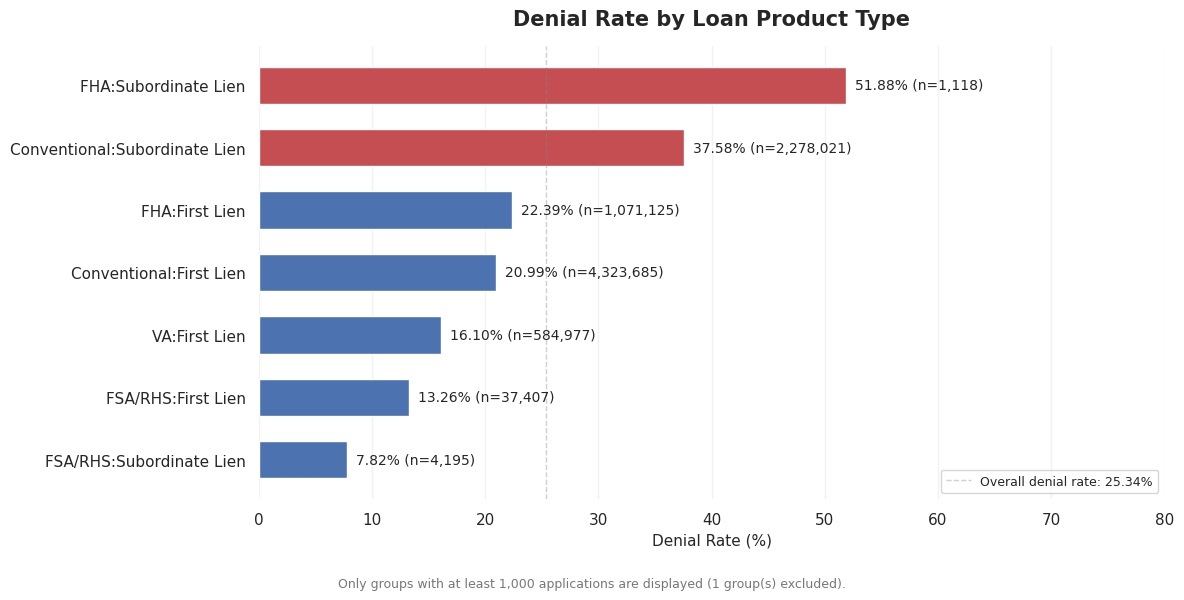

Updated: /content/drive/MyDrive/hmda/rq3_spark/denial_by_derived_loan_product_type.png
Groups displayed: 7/8
Groups excluded from chart: 1



In [6]:
# RQ3.1 - Denial rates by loan characteristics
# Only visualize groups with at least 1,000 applications

import numpy as np

sns.set_theme(style="whitegrid")

MIN_SAMPLE = 1000
Z = 1.96

TITLES = {
    "lien_status": "Denial Rate by Lien Status",
    "occupancy_type": "Denial Rate by Occupancy Type",
    "construction_method": "Denial Rate by Construction Method",
    "derived_loan_product_type": "Denial Rate by Loan Product Type"
}


# Calculate Wilson confidence intervals
def wilson_ci(denied, n, z=1.96):

    p = denied / n
    denominator = 1 + z**2 / n

    center = (p + z**2 / (2 * n)) / denominator

    margin = (
        z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
        / denominator
    )

    lower = np.clip(center - margin, 0, 1)
    upper = np.clip(center + margin, 0, 1)

    return lower * 100, upper * 100


for col, title in TITLES.items():

    # Full statistical results
    df_full = RQ3_RESULTS[col].copy()

    df_full["ci_lower"], df_full["ci_upper"] = wilson_ci(
        df_full["denied"],
        df_full["applications"],
        Z
    )

    df_full["low_sample"] = (
        df_full["applications"] < MIN_SAMPLE
    )

    # Preserve all groups in result dictionary
    RQ3_RESULTS[col] = df_full.copy()

    # Overwrite existing CSV without filtering
    df_full.to_csv(
        os.path.join(OUT, f"denial_by_{col}.csv"),
        index=False
    )

    # Filter only for visualization
    df = df_full[
        df_full["applications"] >= MIN_SAMPLE
    ].copy()

    excluded = len(df_full) - len(df)

    df = df.sort_values(
        "denial_rate", ascending=True
    ).reset_index(drop=True)

    # Red: above baseline
    # Blue: below baseline
    colors = [
        "#C44E52" if rate > BASELINE else "#4C72B0"
        for rate in df["denial_rate"]
    ]

    fig, ax = plt.subplots(
        figsize=(12, max(4, len(df) * 0.65 + 1.5))
    )

    # Horizontal bar chart
    bars = ax.barh(
        df["label"].astype(str),
        df["denial_rate"],
        color=colors,
        height=0.6
    )

    # Overall denial rate
    ax.axvline(
        BASELINE,
        color="#888888",
        linestyle="--",
        linewidth=1,
        alpha=0.4,
        label=f"Overall denial rate: {BASELINE:.2f}%"
    )

    # Add denial rate and application volume
    for bar, rate, n in zip(
        bars,
        df["denial_rate"],
        df["applications"]
    ):

        ax.text(
            rate + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f"{rate:.2f}% (n={n:,})",
            va="center",
            fontsize=10
        )

    # Chart formatting
    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Denial Rate (%)", fontsize=11)
    ax.set_ylabel("")
    ax.set_xlim(0, 80)

    ax.legend(
        loc="lower right",
        frameon=True,
        fontsize=9
    )

    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)

    sns.despine(left=True, bottom=True)

    # Sample size note
    if excluded > 0:

        fig.text(
            0.5,
            0.015,
            f"Only groups with at least {MIN_SAMPLE:,} "
            f"applications are displayed "
            f"({excluded} group(s) excluded).",
            ha="center",
            fontsize=9,
            color="#777777"
        )

        plt.tight_layout(rect=[0, 0.05, 1, 1])

    else:

        plt.tight_layout()

    # Overwrite existing chart
    filepath = os.path.join(
        OUT, f"denial_by_{col}.png"
    )

    fig.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print(f"Updated: {filepath}")
    print(f"Groups displayed: {len(df)}/{len(df_full)}")
    print(f"Groups excluded from chart: {excluded}\n")

## RQ3.2 — Geographic Analysis

In [7]:
# RQ3.2 - Denial rate by state

state_results = denial_summary(S1, "state_code")

# Store missing state records separately
state_missing = state_results[
    state_results["state_code"].isna()
].copy()

# Valid geographic records
state_results = state_results[
    state_results["state_code"].notna()
].copy()

state_results = state_results.sort_values(
    "denial_rate", ascending=False
).reset_index(drop=True)

# Save results
RQ3_RESULTS["state_code"] = state_results

state_results.to_csv(
    OUT + "denial_by_state.csv", index=False
)

state_missing.to_csv(
    OUT + "missing_state_summary.csv", index=False
)

print(f"Overall denial rate: {BASELINE:.2f}%")
print(f"Number of states/territories: {len(state_results)}")

display(state_results.round(2))

print("\nMissing state records:")
display(state_missing.round(2))

Overall denial rate: 25.34%
Number of states/territories: 54


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
0,MS,72904,23281,49623,31.93,0.88,6.59
1,LA,91609,29234,62375,31.91,1.10,6.57
2,HI,23327,7190,16137,30.82,0.28,5.48
3,FL,683860,207409,476451,30.33,8.24,4.99
4,WV,38419,11271,27148,29.34,0.46,4.00
5,GA,316285,88543,227742,27.99,3.81,2.65
6,AL,144489,39905,104584,27.62,1.74,2.28
7,TX,679129,184473,494656,27.16,8.18,1.82
8,NJ,215234,58375,156859,27.12,2.59,1.78
9,NM,50036,13434,36602,26.85,0.60,1.51



Missing state records:


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
0,None,36577,31465,5112,86.02,0.44,60.68


In [8]:
# Geographic summary statistics

print("Denial rate distribution across states:")

display(
    state_results["denial_rate"]
    .describe()
    .round(2)
)

print("\nTop 10 highest denial rates:")

display(
    state_results.nlargest(10, "denial_rate")
    .round(2)
)

print("\nTop 10 lowest denial rates:")

display(
    state_results.nsmallest(10, "denial_rate")
    .round(2)
)

print("\nTop 10 states by application volume:")

display(
    state_results.nlargest(10, "applications")
    .round(2)
)

Denial rate distribution across states:


,denial_rate
count,54.00
mean,23.50
std,4.32
min,9.68
25%,21.10
50%,23.96
75%,26.21
max,31.93



Top 10 highest denial rates:


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
0,MS,72904,23281,49623,31.93,0.88,6.59
1,LA,91609,29234,62375,31.91,1.10,6.57
2,HI,23327,7190,16137,30.82,0.28,5.48
3,FL,683860,207409,476451,30.33,8.24,4.99
4,WV,38419,11271,27148,29.34,0.46,4.00
5,GA,316285,88543,227742,27.99,3.81,2.65
6,AL,144489,39905,104584,27.62,1.74,2.28
7,TX,679129,184473,494656,27.16,8.18,1.82
8,NJ,215234,58375,156859,27.12,2.59,1.78
9,NM,50036,13434,36602,26.85,0.60,1.51



Top 10 lowest denial rates:


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
53,GU,124,12,112,9.68,0.00,-15.66
52,ND,15351,2244,13107,14.62,0.18,-10.72
51,IA,81055,13306,67749,16.42,0.98,-8.93
50,SD,19267,3371,15896,17.50,0.23,-7.85
49,MN,136569,23926,112643,17.52,1.65,-7.82
48,NE,46622,8266,38356,17.73,0.56,-7.61
47,WI,167105,29743,137362,17.80,2.01,-7.54
46,VI,44,8,36,18.18,0.00,-7.16
45,KS,67639,13548,54091,20.03,0.81,-5.31
44,VT,14713,2963,11750,20.14,0.18,-5.20



Top 10 states by application volume:


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
15,CA,691809,180539,511270,26.10,8.33,0.76
3,FL,683860,207409,476451,30.33,8.24,4.99
7,TX,679129,184473,494656,27.16,8.18,1.82
21,NC,342338,85548,256790,24.99,4.12,-0.35
19,PA,328267,82238,246029,25.05,3.95,-0.29
25,OH,325801,79557,246244,24.42,3.93,-0.92
5,GA,316285,88543,227742,27.99,3.81,2.65
12,NY,283359,74541,208818,26.31,3.41,0.96
20,MI,274802,68679,206123,24.99,3.31,-0.35
26,IL,273687,66078,207609,24.14,3.30,-1.20


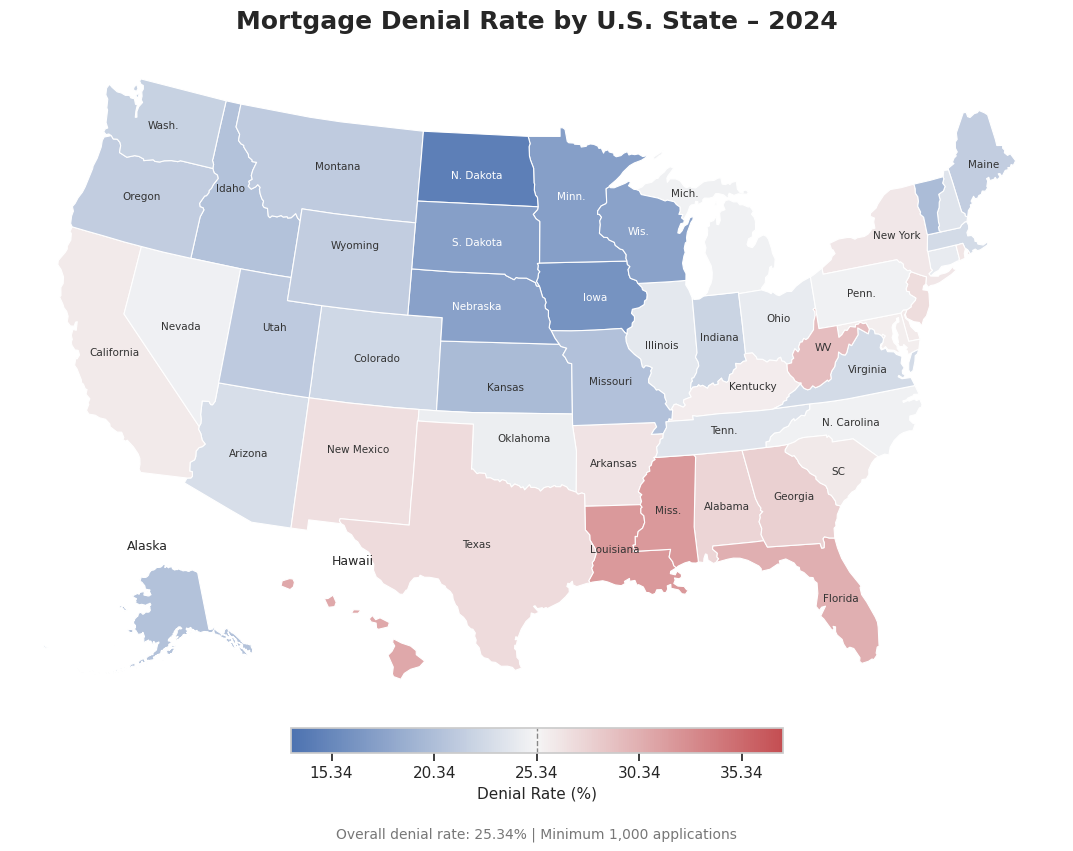

Saved: /content/drive/MyDrive/hmda/rq3_spark/denial_rate_us_map.png


In [9]:
# RQ3.2 - Static US Choropleth Map

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Load US state boundaries
url = (
    "https://raw.githubusercontent.com/PublicaMundi/"
    "MappingAPI/master/data/geojson/us-states.json"
)

us_map = gpd.read_file(url)

# Convert state names to state codes


import us

us_map["state_code"] = us_map["name"].apply(
    lambda name: us.states.lookup(name).abbr
    if us.states.lookup(name) else None
)

# Merge geographic boundaries with denial rate results
map_df = us_map.merge(
    state_results,
    on="state_code",
    how="left"
)

# Continental United States
mainland = map_df[
    map_df["state_code"].notna() & ~map_df["state_code"].isin(
        ["AK", "HI", "PR", "GU", "VI"]
    )
].to_crs("EPSG:5070")

# Alaska and Hawaii
alaska = map_df[
    map_df["state_code"] == "AK"
].to_crs("EPSG:3338")

hawaii = map_df[
    map_df["state_code"] == "HI"
].to_crs("EPSG:3759")

# Diverging color scale centered at overall denial rate
cmap = LinearSegmentedColormap.from_list(
    "denial_rate",
    ["#4C72B0", "#F5F5F5", "#C44E52"]
)

norm = TwoSlopeNorm(
    vmin=BASELINE - 12,
    vcenter=BASELINE,
    vmax=BASELINE + 12
)

fig, ax = plt.subplots(figsize=(14, 9))

plot_params = {
    "column": "denial_rate",
    "cmap": cmap,
    "norm": norm,
    "edgecolor": "white",
    "linewidth": 0.8,
    "missing_kwds": {"color": "#DDDDDD"}
}

# Main map
mainland.plot(ax=ax, **plot_params)

ax.set_axis_off()

# Alaska inset
ax_ak = ax.inset_axes([0.02, 0.01, 0.22, 0.23])

alaska.plot(ax=ax_ak, **plot_params)
ax_ak.set_axis_off()
ax_ak.set_title("Alaska", fontsize=9)

# Hawaii inset
ax_hi = ax.inset_axes([0.25, 0.02, 0.15, 0.18])

hawaii.plot(ax=ax_hi, **plot_params)
ax_hi.set_axis_off()
ax_hi.set_title("Hawaii", fontsize=9)

# Add state name labels

SHORT_NAMES = {
    "WA": "Wash.",
    "CA": "California",
    "ND": "N. Dakota",
    "SD": "S. Dakota",
    "NE": "Nebraska",
    "MN": "Minn.",
    "WI": "Wis.",
    "MI": "Mich.",
    "PA": "Penn.",
    "NY": "New York",
    "WV": "WV",
    "VA": "Virginia",
    "NC": "N. Carolina",
    "SC": "SC",
    "TN": "Tenn.",
    "KY": "Kentucky",
    "MS": "Miss.",
    "AL": "Alabama",
    "LA": "Louisiana",
    "AR": "Arkansas",
    "OK": "Oklahoma",
    "NM": "New Mexico",
    "IN": "Indiana",
    "IL": "Illinois"
}

# Skip states with limited labeling space
SKIP_LABELS = [
    "DC", "DE", "RI", "CT",
    "NJ", "MD", "MA", "VT", "NH"
]

for _, row in mainland.iterrows():

    code = row["state_code"]

    if code in SKIP_LABELS:
        continue

    # Ensure label is positioned inside the state
    point = row.geometry.representative_point()

    label = SHORT_NAMES.get(code, row["name"])

    # Determine text color based on map background
    rate = row["denial_rate"]

    text_color = "#333333"

    if pd.notna(rate):
        if abs(rate - BASELINE) > 7:
            text_color = "white"

    ax.text(
        point.x,
        point.y,
        label,
        ha="center",
        va="center",
        fontsize=7.5,
        color=text_color,
        fontweight="medium",
        zorder=5
    )

# Colorbar
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    fraction=0.035,
    pad=0.04,
    shrink=0.65
)

cbar.set_label("Denial Rate (%)", fontsize=11)

cbar.set_ticks([
    BASELINE - 10,
    BASELINE - 5,
    BASELINE,
    BASELINE + 5,
    BASELINE + 10
])

cbar.ax.axvline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1
)

# Title
ax.set_title(
    "Mortgage Denial Rate by U.S. State – 2024",
    fontsize=18,
    fontweight="bold",
    pad=15
)

fig.text(
    0.5,
    0.06,
    f"Overall denial rate: {BASELINE:.2f}% | "
    "Minimum 1,000 applications",
    ha="center",
    fontsize=10,
    color="#777777"
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

# Save static PNG
filepath = os.path.join(
    OUT, "denial_rate_us_map.png"
)

fig.savefig(
    filepath,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print(f"Saved: {filepath}")

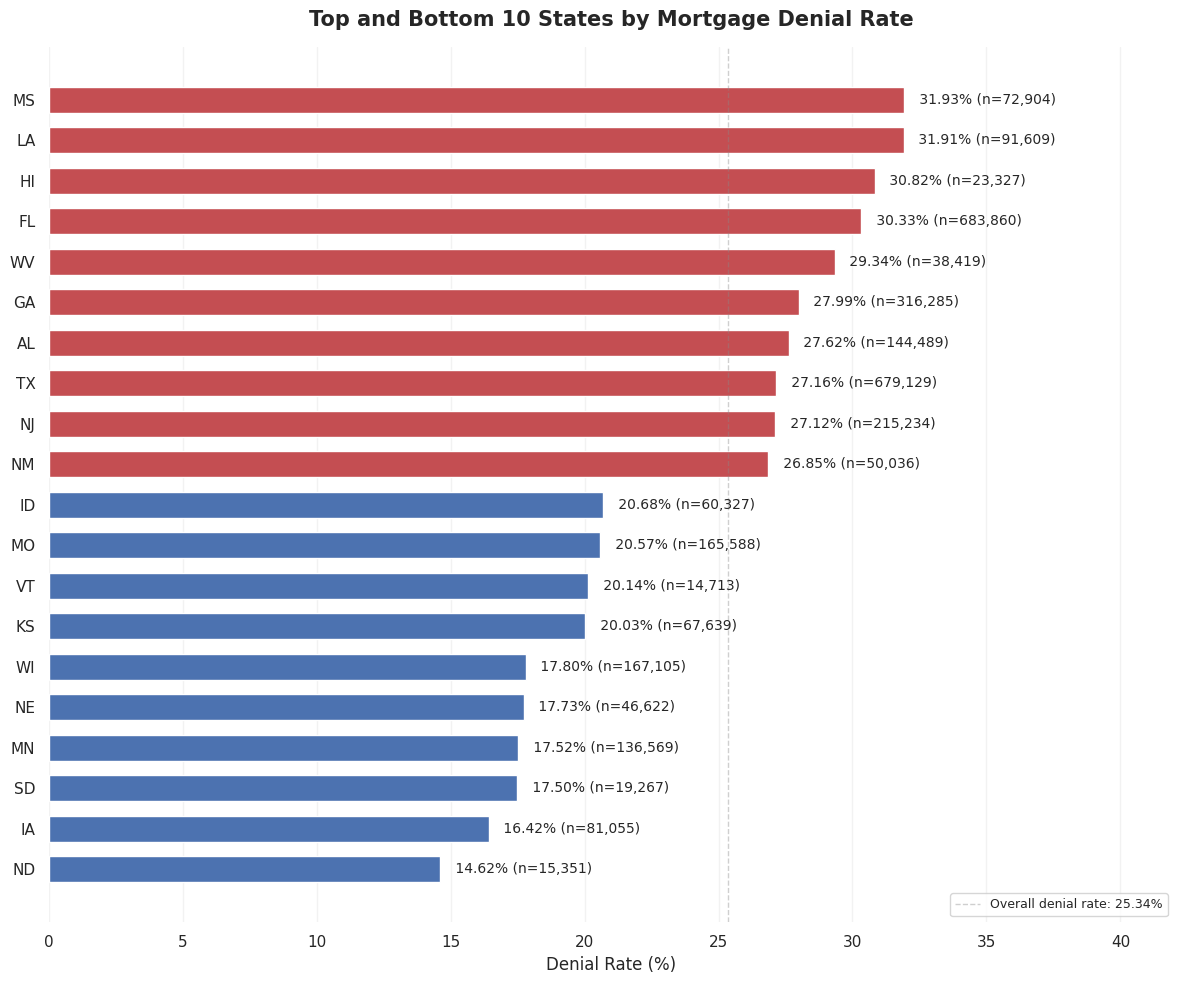

In [10]:
# Top and bottom states by denial rate

# Define state_plot alias to avoid NameError
state_plot = state_results

# Restrict ranking to 50 states and Washington DC
ranking_df = state_plot[
    ~state_plot["state_code"].isin(["PR", "GU", "VI"])
].copy()

top10 = ranking_df.nlargest(10, "denial_rate")
bottom10 = ranking_df.nsmallest(10, "denial_rate")

plot_df = pd.concat(
    [top10, bottom10]
).sort_values("denial_rate", ascending=True)

colors = [
    "#C44E52" if rate > BASELINE else "#4C72B0"
    for rate in plot_df["denial_rate"]
]

fig, ax = plt.subplots(figsize=(12, 10))

bars = ax.barh(
    plot_df["state_code"].astype(str),
    plot_df["denial_rate"],
    color=colors,
    height=0.65
)

ax.axvline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

for bar, rate, n in zip(
    bars,
    plot_df["denial_rate"],
    plot_df["applications"]
):
    ax.text(
        rate + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f" {rate:.2f}% (n={n:,})",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Top and Bottom 10 States by Mortgage Denial Rate",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Denial Rate (%)")
ax.set_ylabel("")
ax.set_xlim(0, 42)

ax.legend(loc="lower right", fontsize=9)

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()

plt.savefig(
    OUT + "denial_rate_top_bottom_states.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

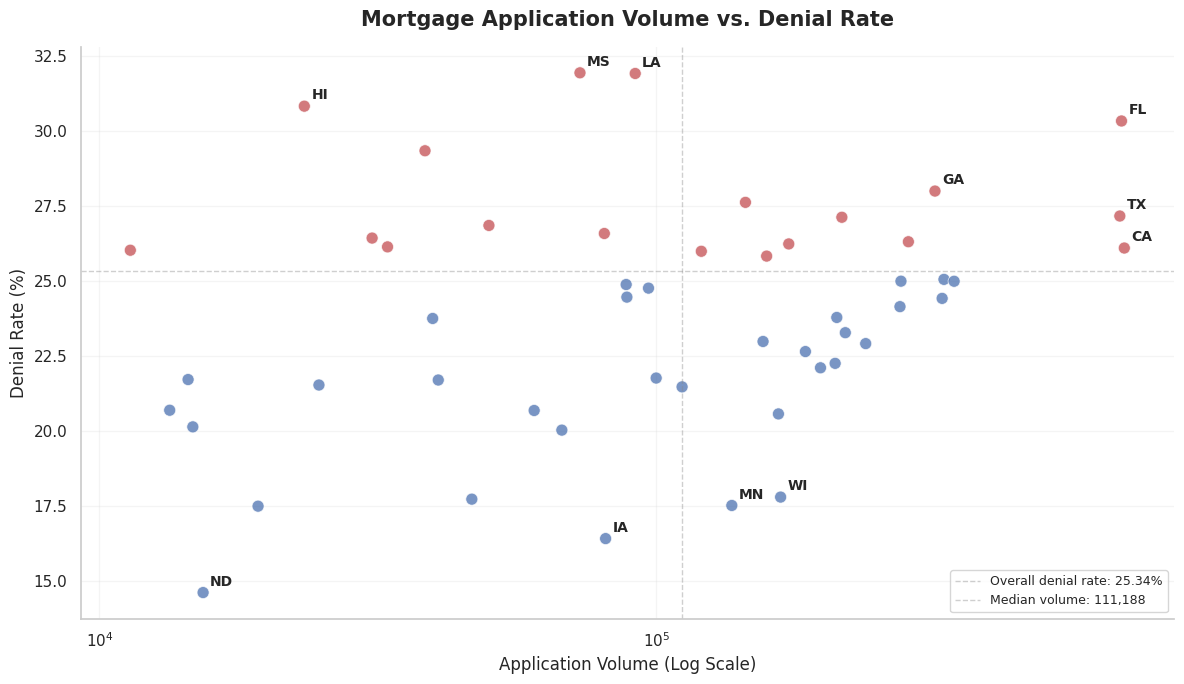

In [11]:
# Application volume versus denial rate

fig, ax = plt.subplots(figsize=(12, 7))

plot_df = ranking_df.copy()

colors = [
    "#C44E52" if rate > BASELINE else "#4C72B0"
    for rate in plot_df["denial_rate"]
]

ax.scatter(
    plot_df["applications"],
    plot_df["denial_rate"],
    c=colors,
    s=75,
    alpha=0.75,
    edgecolors="white",
    linewidth=0.6
)

# Denial rate baseline
ax.axhline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

# Median application volume
median_volume = plot_df["applications"].median()

ax.axvline(
    median_volume,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Median volume: {median_volume:,.0f}"
)

# Highlight important states
highlight = [
    "FL", "CA", "TX", "MS", "LA",
    "HI", "GA", "ND", "IA", "MN", "WI"
]

for _, row in plot_df.iterrows():

    if row["state_code"] in highlight:

        ax.annotate(
            row["state_code"],
            (
                row["applications"],
                row["denial_rate"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold"
        )

ax.set_xscale("log")

ax.set_title(
    "Mortgage Application Volume vs. Denial Rate",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Application Volume (Log Scale)")
ax.set_ylabel("Denial Rate (%)")

ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

sns.despine()

plt.tight_layout()

plt.savefig(
    OUT + "state_volume_vs_denial_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

## RQ3.3 — Lender Analysis

In [12]:
# RQ3.3 - Denial rate by lender

MIN_SAMPLE = 1000

lender_results = denial_summary(S1, "lei")

# Calculate 95% Wilson confidence intervals
lender_results["ci_lower"], lender_results["ci_upper"] = wilson_ci(
    lender_results["denied"],
    lender_results["applications"]
)

# Flag small lenders
lender_results["low_sample"] = (
    lender_results["applications"] < MIN_SAMPLE
)

lender_results = lender_results.sort_values(
    ["applications", "lei"], ascending=[False, True]
).reset_index(drop=True)

# Store full results
RQ3_RESULTS["lei"] = lender_results.copy()

# Save full results
lender_results.to_csv(
    OUT + "denial_by_lender.csv",
    index=False
)

print(f"Total lenders: {len(lender_results):,}")
print(f"Overall denial rate: {BASELINE:.2f}%")

display(lender_results.head(10).round(2))

Total lenders: 4,909
Overall denial rate: 25.34%


,lei,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,ci_lower,ci_upper,low_sample
0,549300FGXN1K3HLB1R50,443360,82289,361071,18.56,5.34,-6.78,18.45,18.68,False
1,549300HW662MN1WU8550,423838,57760,366078,13.63,5.11,-11.71,13.52,13.73,False
2,B4TYDEB6GKMZO031MB27,164085,80920,83165,49.32,1.98,23.97,49.07,49.56,False
3,X05BVSK68TQ7YTOSNR22,147224,112530,34694,76.43,1.77,51.09,76.22,76.65,False
4,6BYL5QZYBDK8S7L73M02,128667,54155,74512,42.09,1.55,16.75,41.82,42.36,False
5,5493003GQDUH26DNNH17,125776,43754,82022,34.79,1.52,9.45,34.52,35.05,False
6,549300AG64NHILB7ZP05,112716,33298,79418,29.54,1.36,4.20,29.28,29.81,False
7,549300XQVJ1XBNFA5536,106837,76563,30274,71.66,1.29,46.32,71.39,71.93,False
8,549300VZVN841I2ILS84,105610,3716,101894,3.52,1.27,-21.82,3.41,3.63,False
9,549300DD5QQUHO6PCH70,97323,23564,73759,24.21,1.17,-1.13,23.94,24.48,False


In [13]:
# Lender sample size distribution

print("Application volume distribution:")

display(
    lender_results["applications"]
    .describe(percentiles=[
        0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
    ])
    .round(2)
)

# Assess coverage at different thresholds
threshold_results = []

for threshold in [100, 500, 1000, 5000, 10000]:

    subset = lender_results[
        lender_results["applications"] >= threshold
    ]

    threshold_results.append({
        "min_applications": threshold,
        "lenders": len(subset),
        "lender_share_pct": (
            len(subset) / len(lender_results) * 100
        ),
        "applications": subset["applications"].sum(),
        "application_coverage_pct": (
            subset["applications"].sum() / N * 100
        ),
        "denied": subset["denied"].sum(),
        "denied_coverage_pct": (
            subset["denied"].sum()
            / DENIED * 100
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(2))

threshold_df.to_csv(
    OUT + "lender_threshold_assessment.csv",
    index=False
)

Application volume distribution:


,applications
count,4909.00
mean,1690.88
std,11627.59
min,1.00
10%,34.00
25%,67.00
50%,167.00
75%,640.00
90%,2179.60
95%,4904.60


,min_applications,lenders,lender_share_pct,applications,application_coverage_pct,denied,denied_coverage_pct
0,100,3134,63.84,8208031,98.89,2092275,99.47
1,500,1397,28.46,7816426,94.17,2036622,96.82
2,1000,904,18.42,7461625,89.89,1972960,93.80
3,5000,244,4.97,6046558,72.85,1708958,81.25
4,10000,124,2.53,5209399,62.76,1554318,73.89


In [14]:
# Filter lenders with sufficient application volume

lender_plot = lender_results[
    lender_results["applications"] >= MIN_SAMPLE
].copy()

print(f"Eligible lenders: {len(lender_plot):,}")

print("\nDenial rate distribution:")

display(
    lender_plot["denial_rate"]
    .describe()
    .round(2)
)

print("\nTop 10 lenders by application volume:")

display(
    lender_plot.nlargest(10, "applications")
    .round(2)
)

print("\nTop 10 highest denial rates:")

display(
    lender_plot.nlargest(10, "denial_rate")
    .round(2)
)

print("\nTop 10 lowest denial rates:")

display(
    lender_plot.nsmallest(10, "denial_rate")
    .round(2)
)

Eligible lenders: 904

Denial rate distribution:


,denial_rate
count,904.00
mean,19.34
std,15.79
min,0.00
25%,6.65
50%,15.94
75%,27.70
max,100.00



Top 10 lenders by application volume:


,lei,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,ci_lower,ci_upper,low_sample
0,549300FGXN1K3HLB1R50,443360,82289,361071,18.56,5.34,-6.78,18.45,18.68,False
1,549300HW662MN1WU8550,423838,57760,366078,13.63,5.11,-11.71,13.52,13.73,False
2,B4TYDEB6GKMZO031MB27,164085,80920,83165,49.32,1.98,23.97,49.07,49.56,False
3,X05BVSK68TQ7YTOSNR22,147224,112530,34694,76.43,1.77,51.09,76.22,76.65,False
4,6BYL5QZYBDK8S7L73M02,128667,54155,74512,42.09,1.55,16.75,41.82,42.36,False
5,5493003GQDUH26DNNH17,125776,43754,82022,34.79,1.52,9.45,34.52,35.05,False
6,549300AG64NHILB7ZP05,112716,33298,79418,29.54,1.36,4.20,29.28,29.81,False
7,549300XQVJ1XBNFA5536,106837,76563,30274,71.66,1.29,46.32,71.39,71.93,False
8,549300VZVN841I2ILS84,105610,3716,101894,3.52,1.27,-21.82,3.41,3.63,False
9,549300DD5QQUHO6PCH70,97323,23564,73759,24.21,1.17,-1.13,23.94,24.48,False



Top 10 highest denial rates:


,lei,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,ci_lower,ci_upper,low_sample
743,549300S347HTLHLOC775,1332,1332,0,100.00,0.02,74.66,99.71,100.00,False
49,549300Q3ROEQU3D1IW91,24176,21223,2953,87.79,0.29,62.44,87.37,88.19,False
467,984500F03B9034CQB904,2307,1987,320,86.13,0.03,60.79,84.66,87.48,False
174,5493000V86JDJLM0OV13,7111,6100,1011,85.78,0.09,60.44,84.95,86.57,False
259,549300FFVDRROF85IC57,4537,3860,677,85.08,0.05,59.74,84.01,86.09,False
362,5493009XSE00M8B9R434,3107,2594,513,83.49,0.04,58.15,82.14,84.75,False
11,549300YIQ7S7Z8PIHE53,90490,74388,16102,82.21,1.09,56.86,81.96,82.45,False
29,549300CB67L6KPJLHE19,60939,48165,12774,79.04,0.73,53.70,78.71,79.36,False
3,X05BVSK68TQ7YTOSNR22,147224,112530,34694,76.43,1.77,51.09,76.22,76.65,False
287,254900DSZI6CJXJL6Z14,4170,3107,1063,74.51,0.05,49.17,73.16,75.81,False



Top 10 lowest denial rates:


,lei,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,ci_lower,ci_upper,low_sample
346,549300DCGBXW5FJMV921,3297,0,3297,0.00,0.04,-25.34,0.00,0.12,False
450,549300C8GOC4OYUV0Z32,2428,0,2428,0.00,0.03,-25.34,0.00,0.16,False
538,549300PRAPL43XPYR044,1973,0,1973,0.00,0.02,-25.34,0.00,0.19,False
549,254900DRSIZBQXDCJ875,1937,0,1937,0.00,0.02,-25.34,0.00,0.20,False
698,9845006B80369D0D9F43,1430,0,1430,0.00,0.02,-25.34,0.00,0.27,False
741,549300ANF834QIIFUE57,1335,0,1335,0.00,0.02,-25.34,0.00,0.29,False
751,549300YX5RPSSMR88K92,1306,0,1306,0.00,0.02,-25.34,0.00,0.29,False
493,549300C1ICNCM0V37Y02,2174,1,2173,0.05,0.03,-25.30,0.01,0.26,False
755,5493004M1U54OO4KKE09,1295,2,1293,0.15,0.02,-25.19,0.04,0.56,False
187,5493006L4FQIQFVFNS72,6725,18,6707,0.27,0.08,-25.07,0.17,0.42,False


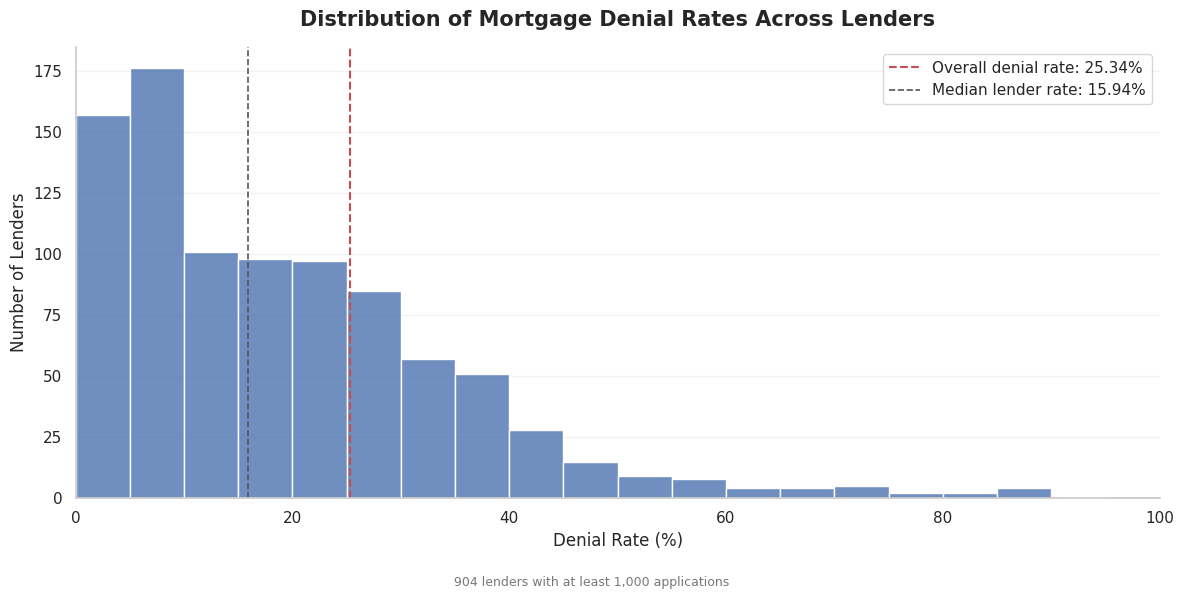

In [15]:
# RQ3.3 - Lender denial rate distribution

fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    data=lender_plot,
    x="denial_rate",
    bins=np.arange(0, 105, 5),
    color="#4C72B0",
    edgecolor="white",
    alpha=0.8,
    ax=ax
)

ax.axvline(
    BASELINE,
    color="#C44E52",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

median_rate = lender_plot["denial_rate"].median()

ax.axvline(
    median_rate,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Median lender rate: {median_rate:.2f}%"
)

ax.set_title(
    "Distribution of Mortgage Denial Rates Across Lenders",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Denial Rate (%)")
ax.set_ylabel("Number of Lenders")
ax.set_xlim(0, 100)

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)

sns.despine()

fig.text(
    0.5, 0.01,
    f"{len(lender_plot):,} lenders with at least "
    f"{MIN_SAMPLE:,} applications",
    ha="center",
    fontsize=9,
    color="#777777"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    OUT + "lender_denial_rate_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

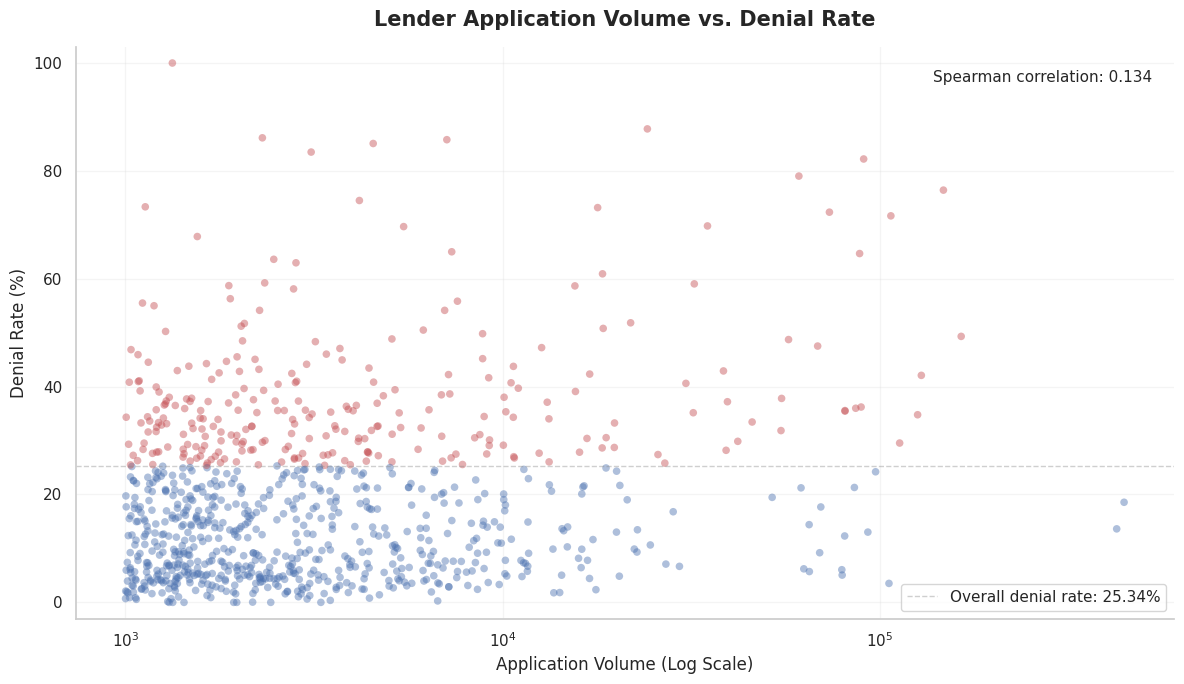

Spearman correlation: 0.1344


In [16]:
# Lender application volume versus denial rate

fig, ax = plt.subplots(figsize=(12, 7))

colors = np.where(
    lender_plot["denial_rate"] > BASELINE,
    "#C44E52",
    "#4C72B0"
)

ax.scatter(
    lender_plot["applications"],
    lender_plot["denial_rate"],
    c=colors,
    alpha=0.45,
    s=30,
    edgecolors="none"
)

ax.axhline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

# Spearman correlation
spearman_corr = lender_plot["applications"].corr(
    lender_plot["denial_rate"],
    method="spearman"
)

ax.text(
    0.98, 0.96,
    f"Spearman correlation: {spearman_corr:.3f}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    fontweight="medium"
)

ax.set_xscale("log")
ax.set_ylim(-3, 103)

ax.set_title(
    "Lender Application Volume vs. Denial Rate",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Application Volume (Log Scale)")
ax.set_ylabel("Denial Rate (%)")

ax.legend(loc="lower right")
ax.grid(alpha=0.2)

sns.despine()

plt.tight_layout()

fig.savefig(
    OUT + "lender_volume_vs_denial_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print(f"Spearman correlation: {spearman_corr:.4f}")

In [17]:
# Create lender size groups

size_df = lender_results.copy()

size_labels = [
    "<100",
    "100–499",
    "500–999",
    "1,000–4,999",
    "5,000–9,999",
    "10,000+"
]

size_df["size_group"] = pd.cut(
    size_df["applications"],
    bins=[0, 100, 500, 1000, 5000, 10000, np.inf],
    labels=size_labels,
    right=False
)

size_summary = (
    size_df.groupby("size_group", observed=True)
    .agg(
        lenders=("lei", "size"),
        applications=("applications", "sum"),
        denied=("denied", "sum"),
        originated=("originated", "sum"),
        mean_lender_rate=("denial_rate", "mean"),
        median_lender_rate=("denial_rate", "median")
    )
    .reset_index()
)

# Application-weighted denial rate
size_summary["denial_rate"] = (
    size_summary["denied"]
    / size_summary["applications"] * 100
)

size_summary["volume_share"] = (
    size_summary["applications"] / N * 100
)

size_summary["gap_vs_baseline_pp"] = (
    size_summary["denial_rate"] - BASELINE
)

display(size_summary.round(2))

size_summary.to_csv(
    OUT + "denial_by_lender_size.csv",
    index=False
)

,size_group,lenders,applications,denied,originated,mean_lender_rate,median_lender_rate,denial_rate,volume_share,gap_vs_baseline_pp
0,<100,1775,92516,11187,81329,12.15,8.24,12.09,1.11,-13.25
1,100–499,1737,391605,55653,335952,13.85,10.38,14.21,4.72,-11.13
2,500–999,493,354801,63662,291139,17.82,14.99,17.94,4.27,-7.40
3,"1,000–4,999",660,1415067,264002,1151065,18.15,15.46,18.66,17.05,-6.68
4,"5,000–9,999",120,837159,154640,682519,18.33,13.42,18.47,10.09,-6.87
5,"10,000+",124,5209399,1554318,3655081,26.66,22.37,29.84,62.76,4.50


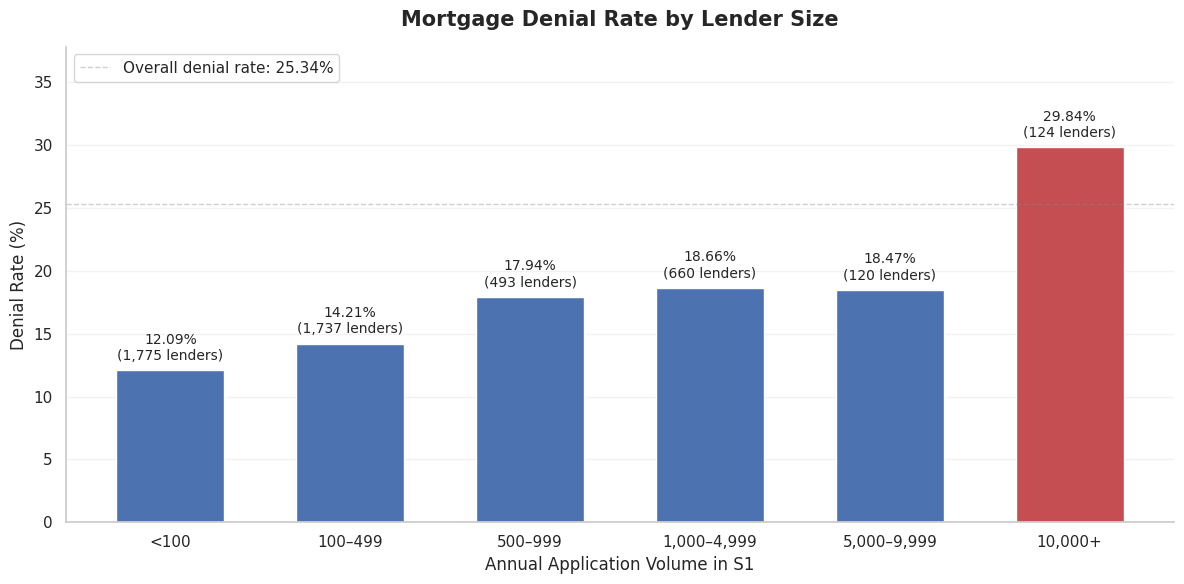

In [18]:
# Denial rate by lender size group

fig, ax = plt.subplots(figsize=(12, 6))

plot_df = size_summary.copy()

colors = [
    "#C44E52" if rate > BASELINE else "#4C72B0"
    for rate in plot_df["denial_rate"]
]

bars = ax.bar(
    plot_df["size_group"].astype(str),
    plot_df["denial_rate"],
    color=colors,
    width=0.6
)

ax.axhline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

for bar, rate, n in zip(
    bars,
    plot_df["denial_rate"],
    plot_df["lenders"]
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 0.6,
        f"{rate:.2f}%\n({n:,} lenders)",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title(
    "Mortgage Denial Rate by Lender Size",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Annual Application Volume in S1")
ax.set_ylabel("Denial Rate (%)")

ax.set_ylim(
    0,
    max(BASELINE, plot_df["denial_rate"].max()) + 8
)

ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)

sns.despine()

plt.tight_layout()

fig.savefig(
    OUT + "denial_by_lender_size.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

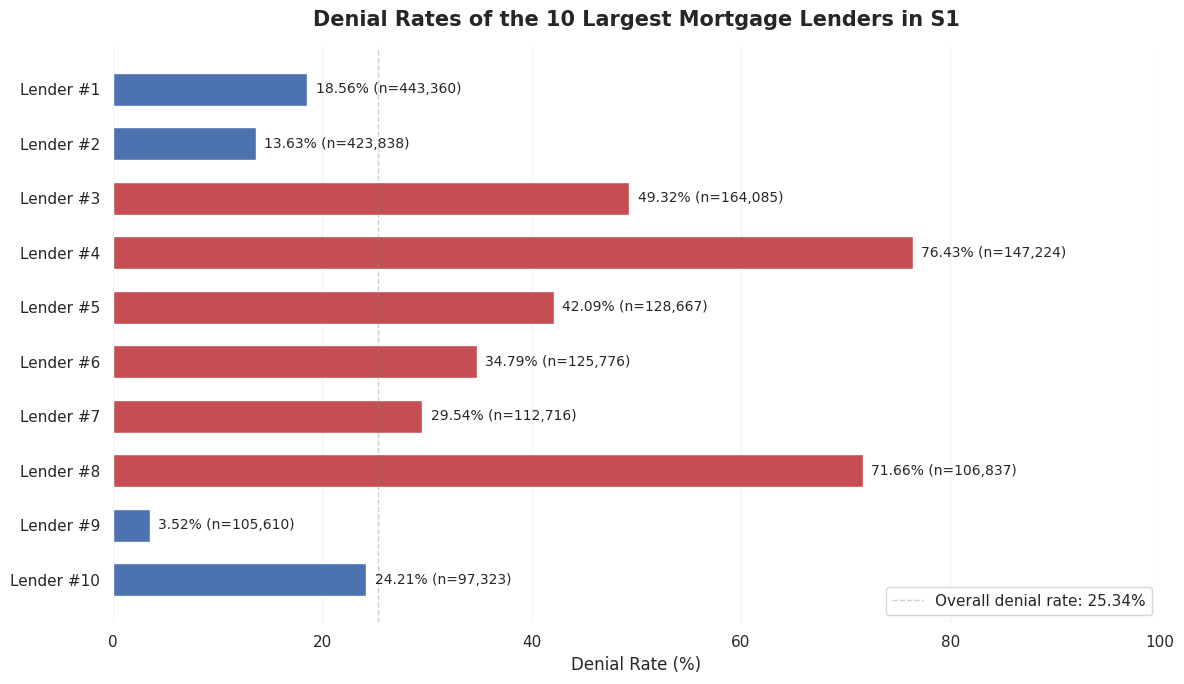

In [19]:
# Top 10 largest lenders

top_lenders = (
    lender_results.nlargest(10, "applications")
    .copy()
    .reset_index(drop=True)
)

top_lenders["rank"] = np.arange(1, 11)

top_lenders["label"] = (
    "Lender #" + top_lenders["rank"].astype(str)
)

top_lenders.to_csv(
    OUT + "top_10_lenders.csv",
    index=False
)

plot_df = top_lenders.sort_values(
    "rank", ascending=False
)

colors = [
    "#C44E52" if rate > BASELINE else "#4C72B0"
    for rate in plot_df["denial_rate"]
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    plot_df["label"],
    plot_df["denial_rate"],
    color=colors,
    height=0.6
)

ax.axvline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

for bar, rate, n in zip(
    bars,
    plot_df["denial_rate"],
    plot_df["applications"]
):

    ax.text(
        rate + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}% (n={n:,})",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Denial Rates of the 10 Largest Mortgage Lenders in S1",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Denial Rate (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)

ax.legend(loc="lower right")

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    OUT + "top_10_lenders_denial_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

## RQ3.4 — Lender Portfolio Diagnostics
Extreme groups are selected from eligible lenders by observed denial rate. Ties use application volume descending, then LEI ascending. These groups are exploratory and not causal.

In [20]:
high_lenders = lender_plot.nlargest(10,'denial_rate')['lei'].tolist()
low_lenders = lender_plot.nsmallest(10,'denial_rate')['lei'].tolist()
portfolio_groups = {'High-denial lenders': S1.filter(F.col('lei').isin(high_lenders)),
                    'Low-denial lenders': S1.filter(F.col('lei').isin(low_lenders)), 'All lenders': S1}
group_summary = []
for name, df in portfolio_groups.items():
    r = df.agg(F.countDistinct('lei').alias('lenders'),F.count('*').alias('applications'),F.sum('denied_flag').alias('denied')).first().asDict()
    group_summary.append({'group':name,**r,'denial_rate':r['denied']/r['applications']*100})
portfolio_group_summary = pd.DataFrame(group_summary)
display(portfolio_group_summary.round(2))
portfolio_group_summary.to_csv(OUT+'lender_portfolio_group_summary.csv',index=False)
# Explicit membership for reproducibility
pd.DataFrame([(g, x) for g,xs in [('High-denial lenders',high_lenders),('Low-denial lenders',low_lenders)] for x in xs],columns=['group','lei']).to_csv(OUT+'lender_portfolio_membership.csv',index=False)

,group,lenders,applications,denied,denial_rate
0,High-denial lenders,10,345393,275286,79.70
1,Low-denial lenders,10,23900,21,0.09
2,All lenders,4909,8300547,2103462,25.34


In [21]:
# Compare portfolio composition across lender groups

PORTFOLIO_COLS = [
    "loan_type",
    "loan_purpose",
    "lien_status",
    "construction_method"
]

portfolio_results = {}

for col in PORTFOLIO_COLS:

    results = []

    for name, df in portfolio_groups.items():

        total = int(portfolio_group_summary.loc[portfolio_group_summary['group']==name,'applications'].iloc[0])
        summary = df.groupBy(col).agg(F.count('*').alias('applications'),F.sum('denied_flag').alias('denied')).toPandas()
        summary['portfolio_share'] = summary['applications'] / total * 100
        summary['denial_rate'] = summary['denied'] / summary['applications'] * 100

        summary["group"] = name

        summary["label"] = (
            summary[col].astype(str)
            .map(LABELS[col])
            .fillna(summary[col].astype(str))
        )

        results.append(summary)

    result = pd.concat(results, ignore_index=True)

    portfolio_results[col] = result

    result.to_csv(
        OUT + f"lender_portfolio_{col}.csv",
        index=False
    )

    print(f"\n--- Portfolio composition: {col} ---")

    comparison = result.pivot(
        index="label",
        columns="group",
        values="portfolio_share"
    ).reindex(columns=list(portfolio_groups)).fillna(0)

    display(comparison.round(2))

    print(f"\n--- Denial rate: {col} ---")

    comparison_rate = result.pivot(
        index="label",
        columns="group",
        values="denial_rate"
    ).reindex(columns=list(portfolio_groups))

    display(comparison_rate.round(2))


--- Portfolio composition: loan_type ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Conventional,91.16,89.82,79.53
FHA,7.25,7.78,12.92
FSA/RHS,0.00,0.11,0.50
VA,1.58,2.28,7.05



--- Denial rate: loan_type ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Conventional,79.09,0.07,26.71
FHA,86.38,0.32,22.42
FSA/RHS,100.00,0.00,12.71
VA,84.61,0.18,16.10



--- Portfolio composition: loan_purpose ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Cash-out refinancing,24.32,11.86,14.05
Home improvement,10.44,0.03,11.72
Home purchase,33.37,71.22,50.09
Not applicable,0.00,0.00,0.04
Other purpose,23.32,8.12,12.99
Refinancing,8.55,8.77,11.11


... (6 outputs left out)


--- Portfolio composition: construction_method ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Manufactured home,29.79,0.37,5.47
Site-built,70.21,99.63,94.53



--- Denial rate: construction_method ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Manufactured home,82.67,0.00,59.99
Site-built,78.44,0.09,23.34


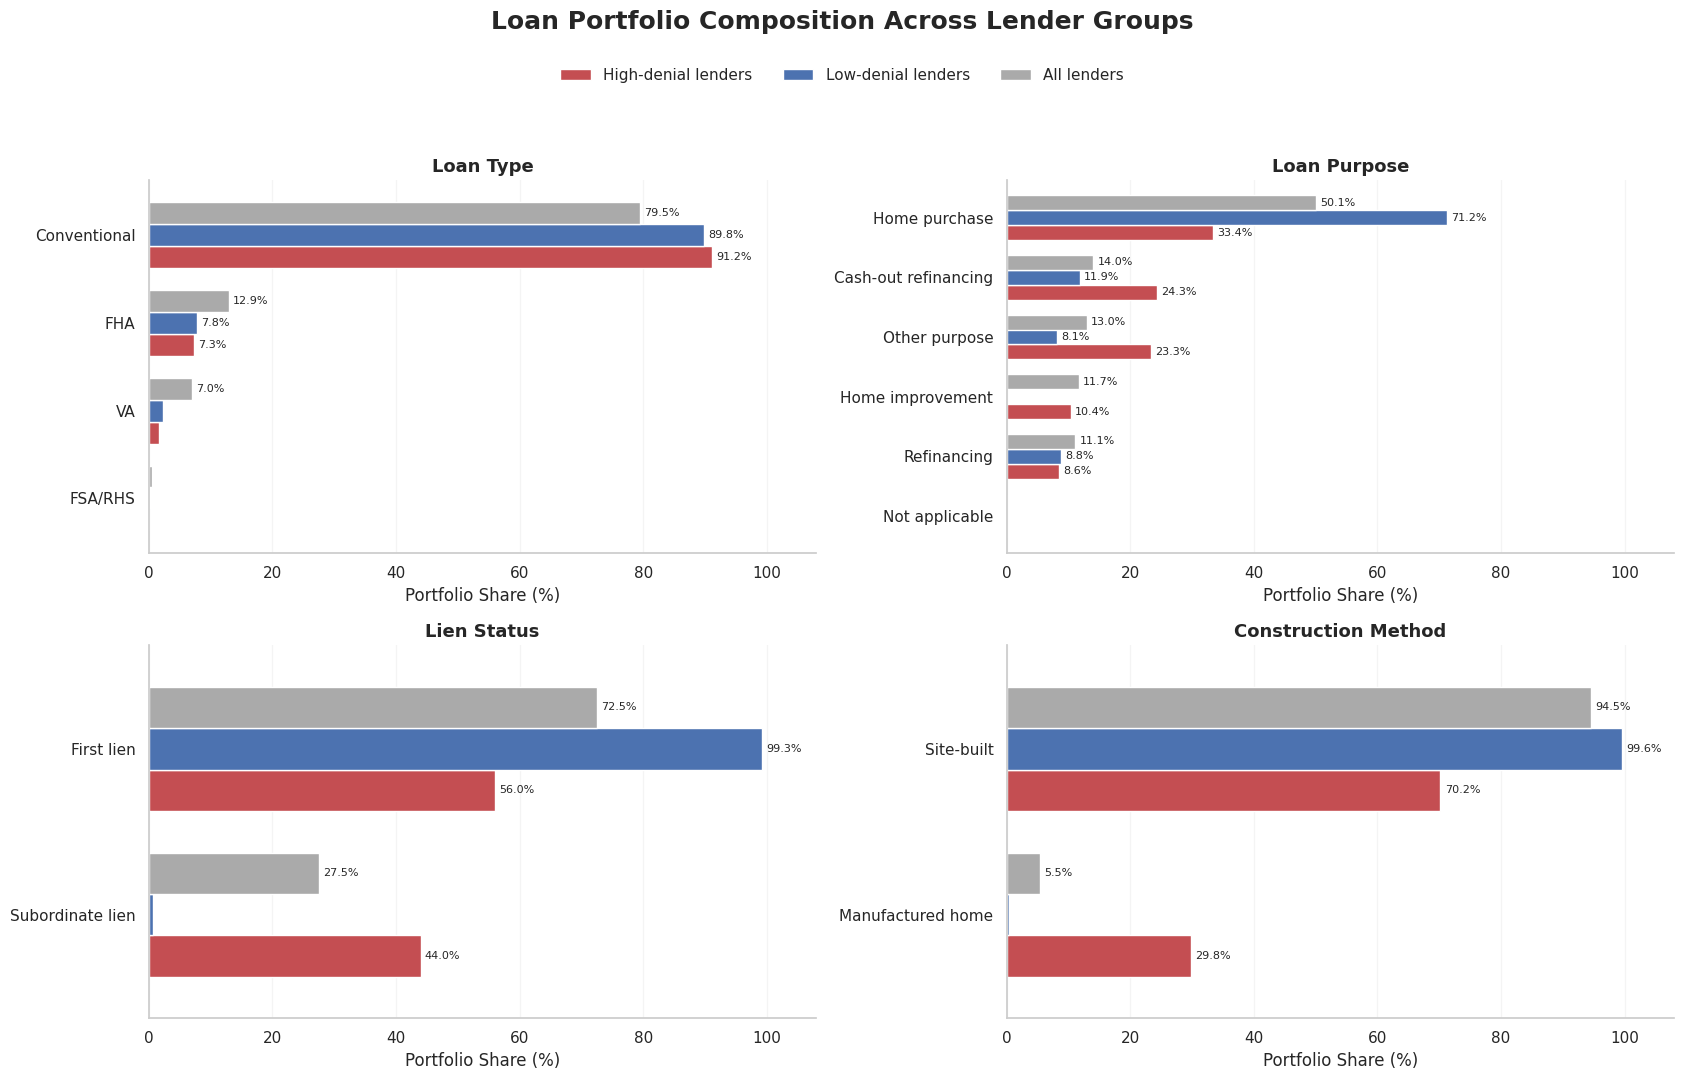

In [22]:
# RQ3.4 - Portfolio composition comparison

GROUP_ORDER = [
    "High-denial lenders",
    "Low-denial lenders",
    "All lenders"
]

GROUP_COLORS = [
    "#C44E52",
    "#4C72B0",
    "#AAAAAA"
]

PORTFOLIO_TITLES = {
    "loan_type": "Loan Type",
    "loan_purpose": "Loan Purpose",
    "lien_status": "Lien Status",
    "construction_method": "Construction Method"
}

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

for ax, (col, title) in zip(
    axes.flatten(),
    PORTFOLIO_TITLES.items()
):

    df = portfolio_results[col].copy()

    pivot = df.pivot(
        index="label",
        columns="group",
        values="portfolio_share"
    ).reindex(columns=GROUP_ORDER).fillna(0)

    pivot = pivot.sort_values(
        "All lenders", ascending=True
    )

    pivot.plot(
        kind="barh",
        ax=ax,
        color=GROUP_COLORS,
        width=0.75,
        legend=False
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Portfolio Share (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 108)

    for container in ax.containers:

        labels = [
            f"{bar.get_width():.1f}%"
            if bar.get_width() >= 3 else ""
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=3,
            fontsize=8
        )

    ax.grid(axis="x", alpha=0.2)
    ax.grid(axis="y", visible=False)

    sns.despine(ax=ax)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Loan Portfolio Composition Across Lender Groups",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

fig.savefig(
    OUT + "lender_portfolio_composition.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

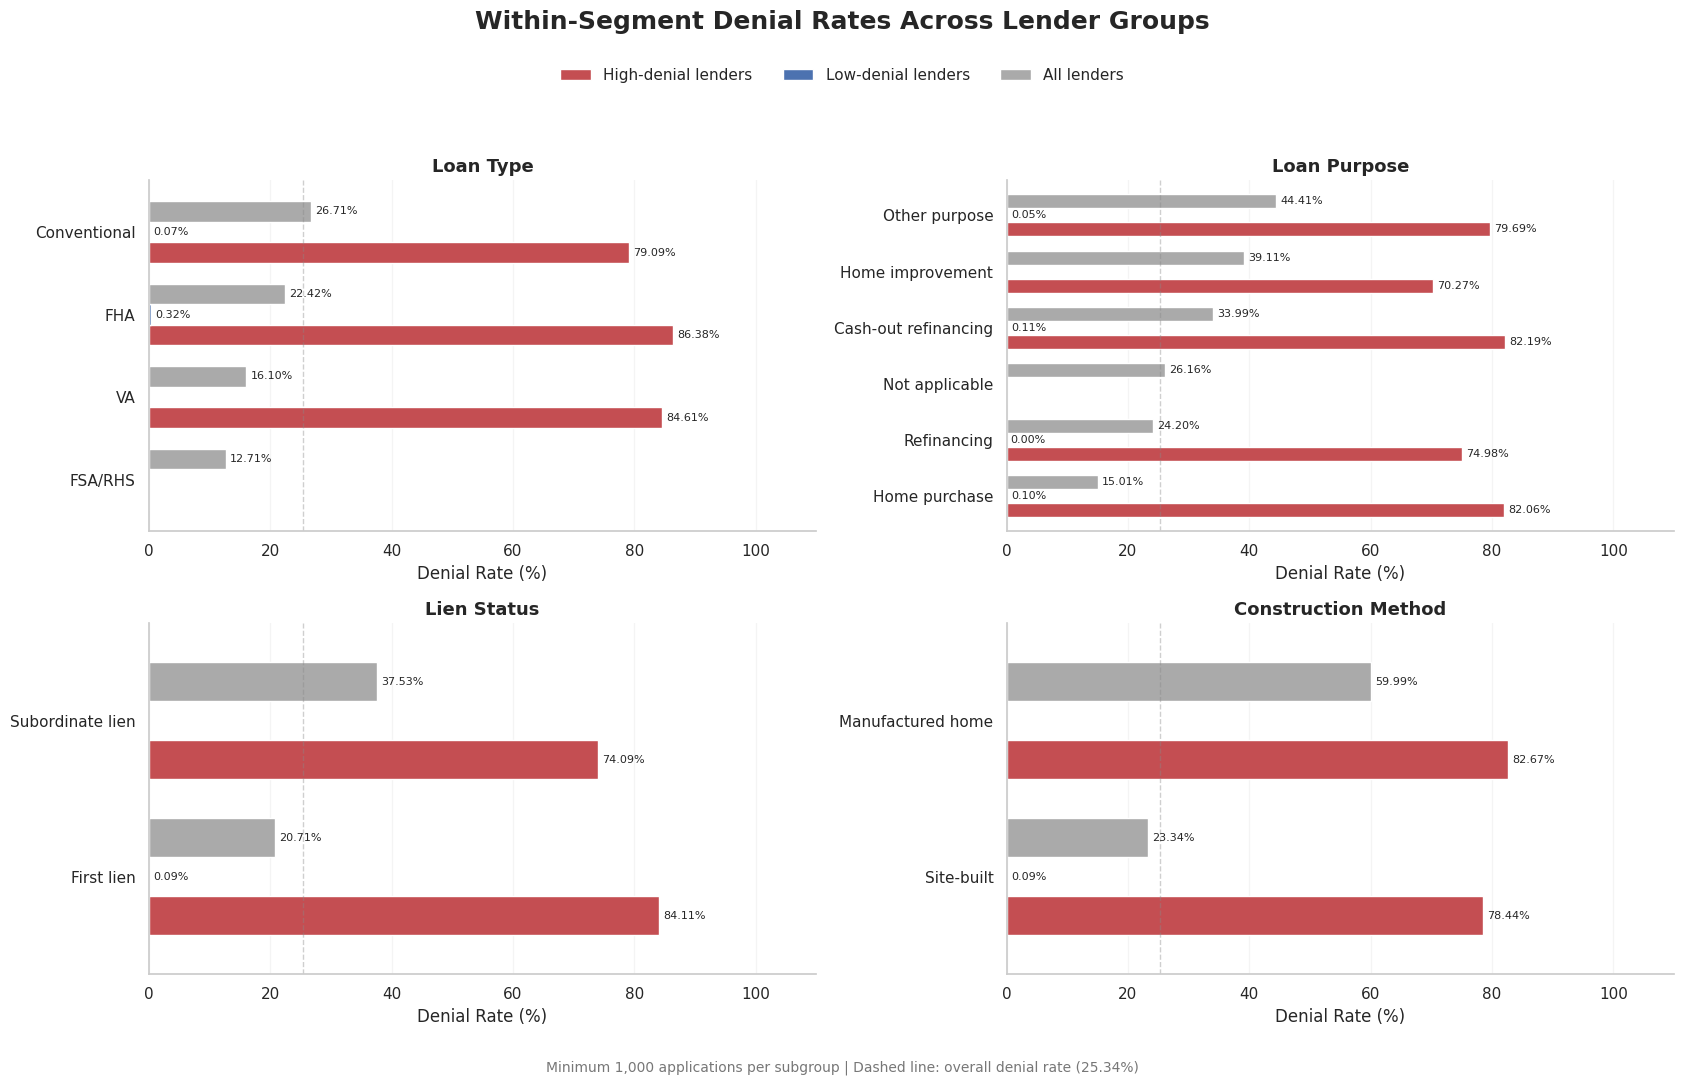

In [23]:
# RQ3.4 - Within-segment denial rate comparison

MIN_SEGMENT_SAMPLE = 1000

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

for ax, (col, title) in zip(
    axes.flatten(),
    PORTFOLIO_TITLES.items()
):

    df = portfolio_results[col].copy()

    # Mask insufficient sample sizes
    df["plot_rate"] = df["denial_rate"].where(
        df["applications"] >= MIN_SEGMENT_SAMPLE
    )

    pivot = df.pivot(
        index="label",
        columns="group",
        values="plot_rate"
    ).reindex(columns=GROUP_ORDER)

    pivot = pivot.dropna(how="all")

    pivot = pivot.sort_values(
        "All lenders", ascending=True
    )

    pivot.plot(
        kind="barh",
        ax=ax,
        color=GROUP_COLORS,
        width=0.75,
        legend=False
    )

    # Overall baseline
    ax.axvline(
        BASELINE,
        color="#888888",
        linestyle="--",
        linewidth=1,
        alpha=0.4
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Denial Rate (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 110)

    for container, group in zip(
        ax.containers, GROUP_ORDER
    ):

        labels = [
            f"{v:.2f}%" if pd.notna(v) else ""
            for v in pivot[group]
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=3,
            fontsize=8
        )

    ax.grid(axis="x", alpha=0.2)
    ax.grid(axis="y", visible=False)

    sns.despine(ax=ax)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Within-Segment Denial Rates Across Lender Groups",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.015,
    f"Minimum {MIN_SEGMENT_SAMPLE:,} applications per subgroup | "
    f"Dashed line: overall denial rate ({BASELINE:.2f}%)",
    ha="center",
    fontsize=10,
    color="#777777"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.90])

fig.savefig(
    OUT + "lender_portfolio_denial_rates.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)